In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/crackathon-data/randomized_dataset/val/labels/023038.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/029467.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/020738.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/030882.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/034602.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/020936.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/037752.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/034138.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/006439.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/002979.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/000870.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/004343.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/013256.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/004396.txt
/kaggl

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anulayakhare/crackathon-data")

print("Path to dataset files:", path)

🚀 Scanning for label files in: /kaggle/input/crackathon-data/randomized_dataset
✅ Found 32385 label files. Reading data...


100%|██████████| 32385/32385 [00:17<00:00, 1818.52it/s]
/tmp/ipykernel_55/1636690905.py:95: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='class_name', order=df['class_name'].value_counts().index, palette='viridis')



📊 DATASET INTELLIGENCE REPORT
Total Labels Scanned: 32385
Total Damage Objects: 55338
Empty Images (Background): 9865
----------------------------------------


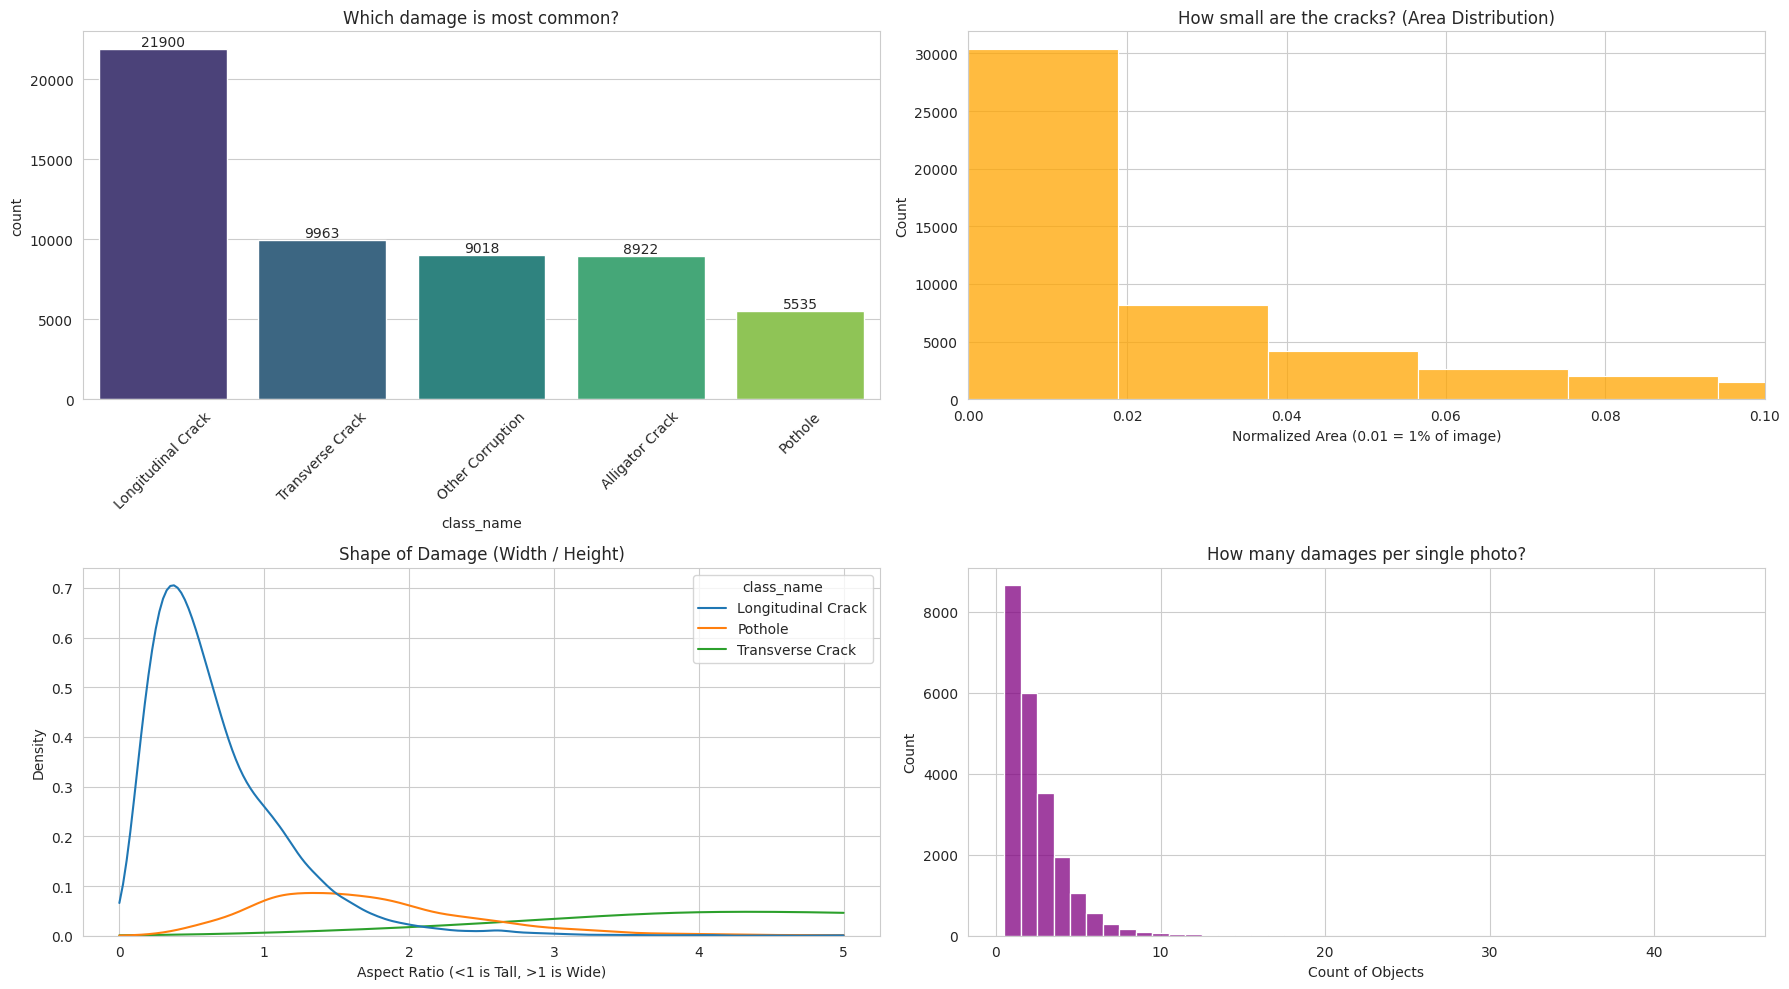


💡 INSTANT RECOMMENDATIONS:
1. Potholes are 10.00% of the data.
2. Average Object Size: 0.0463


In [5]:
import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np

# ==========================================
# 1. SETUP (Fixed for your Kaggle path)
# ==========================================
# Based on your file tree screenshot
DATASET_ROOT = "/kaggle/input/crackathon-data/randomized_dataset"
SEARCH_PATTERN = "**/labels/*.txt"

CLASS_MAP = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Other Corruption",
    4: "Pothole"
}

# ==========================================
# 2. DATA PARSING
# ==========================================
print(f"🚀 Scanning for label files in: {DATASET_ROOT}")
# recursive=True ensures we look inside train/labels AND val/labels
txt_files = glob.glob(os.path.join(DATASET_ROOT, SEARCH_PATTERN), recursive=True)

print(f"✅ Found {len(txt_files)} label files. Reading data...")

data_records = []
empty_count = 0

for file_path in tqdm(txt_files):
    filename = os.path.basename(file_path)
    
    # Check if file is empty (No damage in image)
    if os.path.getsize(file_path) == 0:
        empty_count += 1
        continue

    with open(file_path, 'r') as f:
        lines = f.readlines()
        
        # Double check for empty lines
        if not lines:
            empty_count += 1
            continue
            
        for line in lines:
            parts = line.strip().split()
            # Safety check: Ensure line has 5 numbers
            if len(parts) >= 5:
                try:
                    cls_id = int(parts[0])
                    x, y, w, h = map(float, parts[1:5])
                    
                    data_records.append({
                        'filename': filename,
                        'class_id': cls_id,
                        'class_name': CLASS_MAP.get(cls_id, "Unknown"),
                        'width': w,
                        'height': h,
                        'area': w * h,
                        'aspect_ratio': w / h if h > 0 else 0
                    })
                except ValueError:
                    continue # Skip malformed lines

# Create the Table
df = pd.DataFrame(data_records)

# ==========================================
# 3. THE ANALYSIS (The "Boring" Truth)
# ==========================================
if len(df) == 0:
    print("\n❌ CRITICAL ERROR: No valid labels found. Check the path again.")
else:
    print("\n" + "="*40)
    print("📊 DATASET INTELLIGENCE REPORT")
    print("="*40)
    print(f"Total Labels Scanned: {len(txt_files)}")
    print(f"Total Damage Objects: {len(df)}")
    print(f"Empty Images (Background): {empty_count}")
    print("-" * 40)

    # VISUALIZATION
    sns.set_style("whitegrid")
    fig = plt.figure(figsize=(18, 10))

    # 1. Class Imbalance (The most important chart)
    plt.subplot(2, 2, 1)
    ax = sns.countplot(data=df, x='class_name', order=df['class_name'].value_counts().index, palette='viridis')
    plt.xticks(rotation=45)
    plt.title("Which damage is most common?")
    for container in ax.containers:
        ax.bar_label(container)

    # 2. Object Size (Do we need high-res?)
    plt.subplot(2, 2, 2)
    sns.histplot(data=df, x='area', bins=50, color='orange')
    plt.title("How small are the cracks? (Area Distribution)")
    plt.xlabel("Normalized Area (0.01 = 1% of image)")
    plt.xlim(0, 0.1) # Zoom in on small objects

    # 3. Shape Analysis (Aspect Ratio)
    plt.subplot(2, 2, 3)
    # Filter for the 3 main types to keep chart clean
    target_classes = ["Longitudinal Crack", "Transverse Crack", "Pothole"]
    sns.kdeplot(data=df[df['class_name'].isin(target_classes)], x='aspect_ratio', hue='class_name', clip=(0, 5))
    plt.title("Shape of Damage (Width / Height)")
    plt.xlabel("Aspect Ratio (<1 is Tall, >1 is Wide)")

    # 4. Damage per Image
    plt.subplot(2, 2, 4)
    counts = df['filename'].value_counts()
    sns.histplot(counts, bins=range(1, 10), discrete=True, color='purple')
    plt.title("How many damages per single photo?")
    plt.xlabel("Count of Objects")

    plt.tight_layout()
    plt.show()

    # ==========================================
    # 4. ACTIONABLE INSIGHTS
    # ==========================================
    print("\n💡 INSTANT RECOMMENDATIONS:")
    
    # Check for Pothole rarity
    pothole_count = len(df[df['class_name'] == 'Pothole'])
    total_count = len(df)
    pothole_pct = (pothole_count / total_count) * 100
    print(f"1. Potholes are {pothole_pct:.2f}% of the data.")
    if pothole_pct < 10:
        print("   -> ALERT: Potholes are rare. You MUST use oversampling or the model will ignore them.")
    
    # Check for Tiny Objects
    avg_area = df['area'].mean()
    print(f"2. Average Object Size: {avg_area:.4f}")
    if avg_area < 0.02:
        print("   -> ALERT: Objects are TINY. Standard YOLOv8n will fail. Use YOLOv8-P6 (1280px) models.")

🚀 Scanning for label files in: /kaggle/input/crackathon-data/randomized_dataset
✅ Found 32385 label files. Reading data...


100%|██████████| 32385/32385 [00:19<00:00, 1692.33it/s]
/tmp/ipykernel_55/999259120.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(



📊 DATASET INTELLIGENCE REPORT
Total Label Files      : 32385
Total Damage Objects   : 55338
Empty Images (No objs) : 9865
Avg Objects / Image    : 2.46
---------------------------------------------


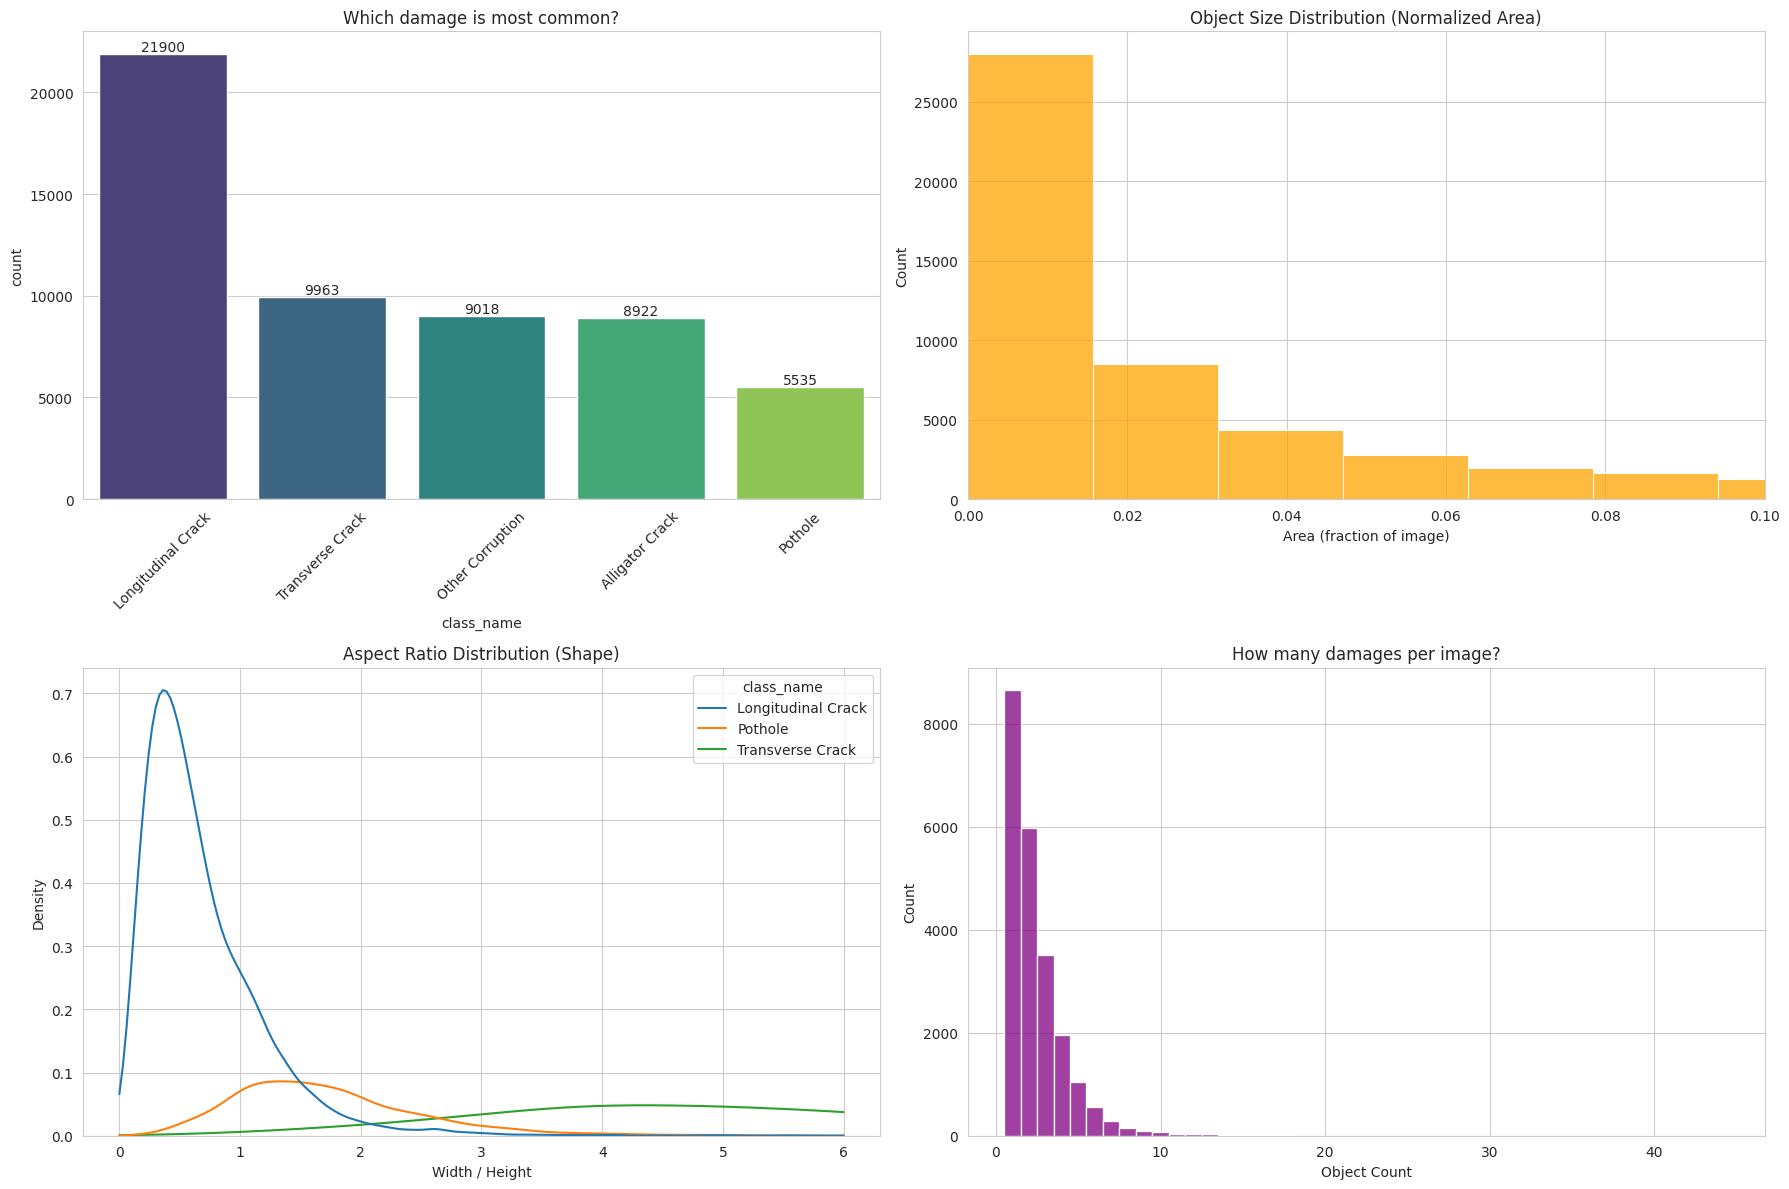

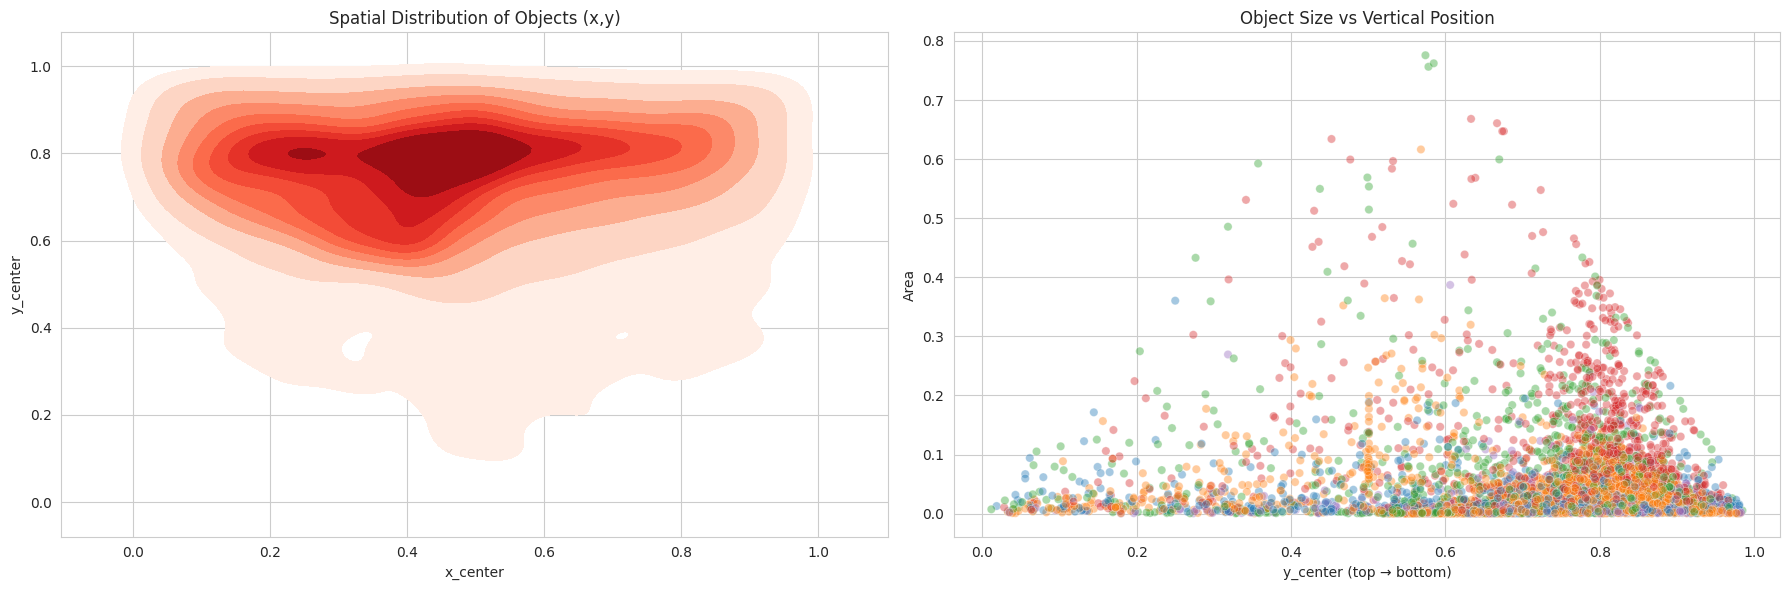


📐 PER-CLASS GEOMETRY SUMMARY
---------------------------------------------
                      area                 aspect_ratio                 
                      0.05    0.50    0.95         0.05    0.50     0.95
class_name                                                              
Alligator Crack     0.0083  0.0827  0.3583       0.5643  1.3610   3.5382
Longitudinal Crack  0.0004  0.0117  0.0992       0.1553  0.5534   1.5941
Other Corruption    0.0011  0.0260  0.2438       0.5193  1.5583   5.2856
Pothole             0.0006  0.0053  0.0635       0.6857  1.6000   3.1917
Transverse Crack    0.0014  0.0108  0.0824       2.0330  5.0715  11.5289

🔗 CLASS CO-OCCURRENCE MATRIX
---------------------------------------------


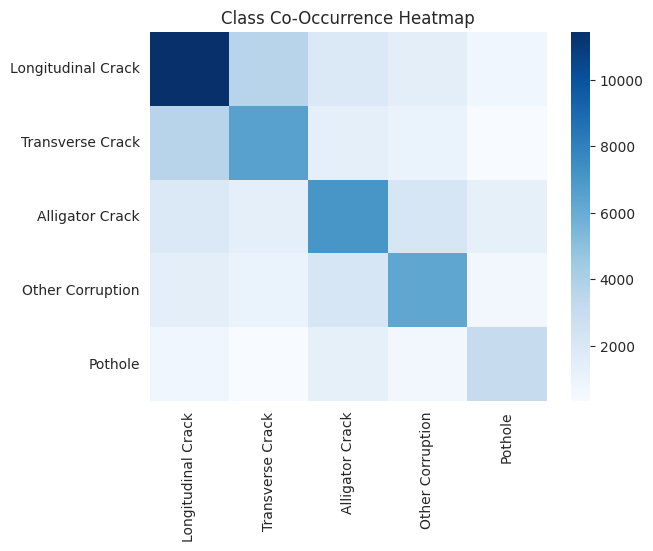


🔍 TINY OBJECT ANALYSIS
---------------------------------------------
Objects < 0.5% area : 25.55%

💡 FINAL MODELING RECOMMENDATIONS
• Potholes share        : 10.00%
• Average object area   : 0.0463
• Tiny objects (<0.5%)  : 25.55%
• Empty images          : 9865 (30.5%)


In [9]:
# ==========================================================
# FULL DATA-SCIENTIST EDA FOR OBJECT DETECTION
# ==========================================================

import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np

# ==========================================================
# 1. SETUP
# ==========================================================

DATASET_ROOT = "/kaggle/input/crackathon-data/randomized_dataset"
SEARCH_PATTERN = "**/labels/*.txt"

CLASS_MAP = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Other Corruption",
    4: "Pothole"
}

sns.set_style("whitegrid")

# ==========================================================
# 2. DATA PARSING
# ==========================================================

print(f"🚀 Scanning for label files in: {DATASET_ROOT}")
txt_files = glob.glob(os.path.join(DATASET_ROOT, SEARCH_PATTERN), recursive=True)

print(f"✅ Found {len(txt_files)} label files. Reading data...")

data_records = []
empty_count = 0

for file_path in tqdm(txt_files):
    filename = os.path.basename(file_path)

    if os.path.getsize(file_path) == 0:
        empty_count += 1
        continue

    with open(file_path, "r") as f:
        lines = f.readlines()
        if not lines:
            empty_count += 1
            continue

        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 5:
                try:
                    cls_id = int(parts[0])
                    x, y, w, h = map(float, parts[1:5])

                    data_records.append({
                        "filename": filename,
                        "class_id": cls_id,
                        "class_name": CLASS_MAP.get(cls_id, "Unknown"),
                        "x_center": x,
                        "y_center": y,
                        "width": w,
                        "height": h,
                        "area": w * h,
                        "aspect_ratio": w / h if h > 0 else np.nan
                    })
                except:
                    continue

df = pd.DataFrame(data_records)

# ==========================================================
# 3. BASIC DATASET SUMMARY
# ==========================================================

print("\n" + "="*45)
print("📊 DATASET INTELLIGENCE REPORT")
print("="*45)

print(f"Total Label Files      : {len(txt_files)}")
print(f"Total Damage Objects   : {len(df)}")
print(f"Empty Images (No objs) : {empty_count}")
print(f"Avg Objects / Image    : {len(df) / (len(txt_files)-empty_count):.2f}")
print("-"*45)

# ==========================================================
# 4. CORE VISUAL EDA (YOUR ORIGINAL + CLEANED)
# ==========================================================

fig = plt.figure(figsize=(18, 12))

# ---- Class Imbalance ----
plt.subplot(2, 2, 1)
ax = sns.countplot(
    data=df,
    x="class_name",
    order=df["class_name"].value_counts().index,
    palette="viridis"
)
plt.xticks(rotation=45)
plt.title("Which damage is most common?")
for c in ax.containers:
    ax.bar_label(c)

# ---- Object Area ----
plt.subplot(2, 2, 2)
sns.histplot(df["area"], bins=60, color="orange")
plt.title("Object Size Distribution (Normalized Area)")
plt.xlabel("Area (fraction of image)")
plt.xlim(0, 0.1)

# ---- Aspect Ratio ----
plt.subplot(2, 2, 3)
focus_classes = ["Longitudinal Crack", "Transverse Crack", "Pothole"]
sns.kdeplot(
    data=df[df["class_name"].isin(focus_classes)],
    x="aspect_ratio",
    hue="class_name",
    clip=(0, 6)
)
plt.title("Aspect Ratio Distribution (Shape)")
plt.xlabel("Width / Height")

# ---- Objects per Image ----
plt.subplot(2, 2, 4)
obj_per_img = df["filename"].value_counts()
sns.histplot(obj_per_img, bins=range(1, 15), color="purple", discrete=True)
plt.title("How many damages per image?")
plt.xlabel("Object Count")

plt.tight_layout()
plt.show()

# ==========================================================
# 5. ADVANCED SPATIAL EDA (VERY IMPORTANT)
# ==========================================================

fig = plt.figure(figsize=(18, 6))

# ---- Object Center Heatmap ----
plt.subplot(1, 2, 1)
sns.kdeplot(x=df["x_center"], y=df["y_center"], cmap="Reds", fill=True)
plt.title("Spatial Distribution of Objects (x,y)")
plt.xlabel("x_center")
plt.ylabel("y_center")

# ---- Area vs Vertical Position ----
plt.subplot(1, 2, 2)
sns.scatterplot(
    data=df.sample(min(6000, len(df))),
    x="y_center",
    y="area",
    hue="class_name",
    alpha=0.4,
    legend=False
)
plt.title("Object Size vs Vertical Position")
plt.xlabel("y_center (top → bottom)")
plt.ylabel("Area")

plt.tight_layout()
plt.show()

# ==========================================================
# 6. PER-CLASS GEOMETRY STATS (NUMERIC)
# ==========================================================

print("\n📐 PER-CLASS GEOMETRY SUMMARY")
print("-"*45)

geom_stats = (
    df.groupby("class_name")[["area", "aspect_ratio"]]
      .quantile([0.05, 0.5, 0.95])
      .unstack()
      .round(4)
)

print(geom_stats)

# ==========================================================
# 7. CO-OCCURRENCE ANALYSIS
# ==========================================================

print("\n🔗 CLASS CO-OCCURRENCE MATRIX")
print("-"*45)

img_class_map = df.groupby("filename")["class_name"].apply(set)

classes = list(CLASS_MAP.values())
co_matrix = pd.DataFrame(0, index=classes, columns=classes)

for cls_set in img_class_map:
    for c1 in cls_set:
        for c2 in cls_set:
            co_matrix.loc[c1, c2] += 1

sns.heatmap(co_matrix, annot=False, cmap="Blues")
plt.title("Class Co-Occurrence Heatmap")
plt.show()

# ==========================================================
# 8. TINY OBJECT RISK ANALYSIS
# ==========================================================

tiny_threshold = 0.005  # 0.5% of image
tiny_ratio = (df["area"] < tiny_threshold).mean() * 100

print("\n🔍 TINY OBJECT ANALYSIS")
print("-"*45)
print(f"Objects < 0.5% area : {tiny_ratio:.2f}%")

# ==========================================================
# 9. FINAL ACTIONABLE RECOMMENDATIONS
# ==========================================================

print("\n💡 FINAL MODELING RECOMMENDATIONS")
print("="*45)

pothole_pct = (df["class_name"] == "Pothole").mean() * 100
avg_area = df["area"].mean()

print(f"• Potholes share        : {pothole_pct:.2f}%")
print(f"• Average object area   : {avg_area:.4f}")
print(f"• Tiny objects (<0.5%)  : {tiny_ratio:.2f}%")
print(f"• Empty images          : {empty_count} ({empty_count/len(txt_files)*100:.1f}%)")



In [1]:
!ls /kaggle/input


crackathon-data


In [2]:
!ls /kaggle/input/crackathon-data

randomized_dataset


In [4]:
!ls /kaggle/input/crackathon-data/randomized_dataset


test  train  val


In [5]:
data_yaml = """
path: /kaggle/input/<DATASET>/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""

with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml created ✅")


data.yaml created ✅


In [6]:
!cat data.yaml



path: /kaggle/input/<DATASET>/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole


In [7]:
!pip install -q ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 35.0 MB/s eta 0:00:00


In [8]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=6,
    project="runs",
    name="rdd_final"
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, k

RuntimeError: Dataset 'data.yaml' error ❌ Dataset 'data.yaml' images not found, missing path '/kaggle/input/<DATASET>/randomized_dataset/val/images'
Note dataset download directory is '/kaggle/working/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

In [9]:
!ls /kaggle/input


crackathon-data


In [10]:
!ls /kaggle/input/crackathon-data


randomized_dataset


In [11]:
!ls /kaggle/input/crackathon-data/randomized_dataset


test  train  val


In [12]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml FIXED ✅")


data.yaml FIXED ✅


In [13]:
!cat data.yaml



path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole


In [14]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=6,
    project="runs",
    name="rdd_final"
)


Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=rdd_final2, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=6, perspective=0.0, plots=True, pose=12.

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78813447fd10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [13]:
!ls -lah /kaggle/working


total 12K
drwxr-xr-x 3 root root 4.0K Jan  8 04:35 .
drwxr-xr-x 5 root root 4.0K Jan  8 04:35 ..
drwxr-xr-x 2 root root 4.0K Jan  8 04:35 .virtual_documents


In [14]:
model = YOLO("runs/detect/rdd_recovery/weights/best.pt")

model.predict(
    source="/kaggle/input/crackathon-data/randomized_dataset/test/images",
    save_txt=True,
    save_conf=True,
    project="predictions",
    name="test"
)


NameError: name 'YOLO' is not defined

In [15]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

!cat data.yaml



path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole


In [16]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=12,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=4,
    project="runs",
    name="rdd_recovery"
)


ModuleNotFoundError: No module named 'ultralytics'

In [17]:
!pip install -q ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 32.9 MB/s eta 0:00:0000:01


In [18]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=12,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=4,
    project="runs",
    name="rdd_recovery"
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, k

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fe3c4b03770>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [19]:
from ultralytics import YOLO

model = YOLO("runs/detect/rdd_recovery/weights/best.pt")
print("Best model loaded ✅")


FileNotFoundError: [Errno 2] No such file or directory: 'runs/detect/rdd_recovery/weights/best.pt'

In [20]:

!find /kaggle/working -type d -name "weights"


/kaggle/working/runs/rdd_recovery/weights


In [21]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/runs/rdd_recovery/weights/best.pt")
print("Best model loaded ✅")


Best model loaded ✅


In [ ]:
model.predict(
    source="/kaggle/input/crackathon-data/randomized_dataset/test/images",
    save_txt=True,
    save_conf=True,
    project="predictions",
    name="test"
)



WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/6000 /kaggle/input/crackathon-data/randomized_dataset/test/images/000004.jpg: 352x640 (no detections), 50.7ms
image 2/6000 /kaggle/input/crackathon-data/randomized_dataset/test/images/000019.jpg: 640x640 (no detections), 16.9ms
image 3/6000 /kaggle/input/crackathon-data/randomized_dataset/test/images/000030.jpg: 640x640 5 longitudinal_cracks, 2 transverse_cracks, 16.2ms
image 4/6000 /kaggle/input/crackathon-data/randomized_dataset/test/images/000

In [2]:
!cd /kaggle/working/predictions/test && ls


labels


In [5]:
!find /kaggle/working -type d -name labels


/kaggle/working/predictions/test/labels


In [7]:
!cd /kaggle/working/predictions/test && ls



labels


In [8]:
!zip -r submission.zip labels


  adding: labels/ (stored 0%)
  adding: labels/015113.txt (deflated 48%)
  adding: labels/015565.txt (deflated 33%)
  adding: labels/016357.txt (deflated 11%)
  adding: labels/018813.txt (deflated 11%)
  adding: labels/013604.txt (deflated 46%)
  adding: labels/016236.txt (deflated 46%)
  adding: labels/021553.txt (deflated 10%)
  adding: labels/013777.txt (deflated 13%)
  adding: labels/001243.txt (deflated 34%)
  adding: labels/020953.txt (deflated 11%)
  adding: labels/024128.txt (deflated 13%)
  adding: labels/003301.txt (deflated 41%)
  adding: labels/017323.txt (deflated 47%)
  adding: labels/007342.txt (deflated 11%)
  adding: labels/021366.txt (deflated 11%)
  adding: labels/013025.txt (deflated 33%)
  adding: labels/008500.txt (deflated 33%)
  adding: labels/003469.txt (deflated 32%)
  adding: labels/013171.txt (deflated 45%)
  adding: labels/013168.txt (deflated 42%)
  adding: labels/013491.txt (deflated 11%)
  adding: labels/008180.txt (deflated 43%)
  adding: labels/020313.

In [6]:
!ls /kaggle/working


In [7]:
!find /kaggle/working -maxdepth 4 -type d


/kaggle/working
/kaggle/working/.virtual_documents


In [1]:
!ls /kaggle/input

crackathon-data


In [2]:
!ls /kaggle/input/crackathon-data/randomized_dataset



test  train  val


In [3]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml ready")


data.yaml ready


In [6]:
!pip install -q ultralytics


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=8,          # VERY SHORT
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=3,
    project="runs",
    name="rdd_model_only"
)


Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=rdd_model_only2, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=3, perspective=0.0, plots=True, pose

In [7]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset

train: train/images
val: val/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("✅ data.yaml fixed")


✅ data.yaml fixed


In [9]:
!pip install -q ultralytics

In [10]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=8,          # VERY SHORT
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=3,
    project="runs",
    name="rdd_model_only"
)


Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=rdd_model_only4, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=3, perspective=0.0, plots=True, pose

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7da37b1efcb0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [11]:
!ls runs/detect/rdd_model_only/weights


ls: cannot access 'runs/detect/rdd_model_only/weights': No such file or directory


In [1]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset

train: train/images
val: val/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("✅ data.yaml fixed")


✅ data.yaml fixed


In [2]:
!pip install -q ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 47.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=30,         
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=3,
    project="runs",
    name="rdd_model_only"
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.250 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, k